In [171]:
# ==========================================
# STEP 1 : Import Libraries
# ==========================================

# Basic Libraries
import os
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# TensorFlow / Keras
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Embedding,
    LSTM,
    Bidirectional,
    Dense,
    Dropout,
    Layer,
    SpatialDropout1D
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from tensorflow.keras.optimizers import Adam

# Scikit-Learn
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score

# Progress Bar
from tqdm.auto import tqdm

print("TensorFlow Version :", tf.__version__)
print("NumPy Version      :", np.__version__)
print("Pandas Version     :", pd.__version__)

TensorFlow Version : 2.20.0
NumPy Version      : 2.0.2
Pandas Version     : 2.3.3


In [172]:
# ==========================================
# Reproducibility
# ==========================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random Seed Set :", SEED)

Random Seed Set : 42


In [173]:
# ==========================================
# Check GPU
# ==========================================

gpus = tf.config.list_physical_devices("GPU")

if gpus:
    print(f"✅ GPU Detected : {gpus[0].name}")
else:
    print("❌ GPU Not Detected")

✅ GPU Detected : /physical_device:GPU:0


In [174]:
# ==========================================
# Global Configuration
# ==========================================

MAX_VOCAB_SIZE = 50000      # Maximum vocabulary
MAX_LEN = 384               # Maximum sequence length
EMBEDDING_DIM = 100         # GloVe 100d

BATCH_SIZE = 32
EPOCHS = 20

N_SPLITS = 5

print("Configuration Loaded Successfully")

Configuration Loaded Successfully


In [175]:
# ==========================================
# STEP 2 : Load Dataset
# ==========================================

TRAIN_PATH = "/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv"
TEST_PATH = "/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv"

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

print("=" * 50)
print("Train Shape :", train.shape)
print("Test Shape  :", test.shape)
print("=" * 50)

Train Shape : (2000, 8)
Test Shape  : (500, 7)


In [176]:
# ==========================================
# View Dataset
# ==========================================

print("Train Dataset")
display(train.head())

print("\nTest Dataset")
display(test.head())

Train Dataset


,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A



Test Dataset


,id,prompt,A,B,C,D,E
0,1,Pick the best possible answer: What is the rel...,"For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p..."
1,2,"What is the estimated redshift of CEERS-93316,...","Approximately z = 6.0, corresponding to 1 bill...","Approximately z = 16.7, corresponding to 235.8...","Approximately z = 3.0, corresponding to 5 bill...","Approximately z = 10.0, corresponding to 13 bi...","Approximately z = 13.0, corresponding to 30 bi..."
2,3,Pick the best possible answer: What is the rea...,The sun appears yellowish due to a reflection ...,"The longer wavelengths of light, such as red a...",The sun appears yellowish due to the scatterin...,The sun emits a yellow light due to its own sp...,The atmosphere absorbs the shorter wavelengths...
3,4,What is the significance of the redshift-dista...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...
4,5,What is the Landau-Lifshitz-Gilbert equation u...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...


In [177]:
# ==========================================
# Dataset Information
# ==========================================

print("TRAIN INFO")
print("-" * 40)
train.info()

print("\nTEST INFO")
print("-" * 40)
test.info()

TRAIN INFO
----------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2000 non-null   int64 
 1   prompt  2000 non-null   object
 2   A       2000 non-null   object
 3   B       2000 non-null   object
 4   C       2000 non-null   object
 5   D       2000 non-null   object
 6   E       2000 non-null   object
 7   answer  2000 non-null   object
dtypes: int64(1), object(7)
memory usage: 125.1+ KB

TEST INFO
----------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      500 non-null    int64 
 1   prompt  500 non-null    object
 2   A       500 non-null    object
 3   B       500 non-null    object
 4   C       500 non-null    object
 5   D       500 non-n

In [178]:
# ==========================================
# Missing Values
# ==========================================

print("Train Missing Values")
display(train.isnull().sum())

print("\nTest Missing Values")
display(test.isnull().sum())

Train Missing Values


id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64


Test Missing Values


id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
dtype: int64

In [179]:
# ==========================================
# Duplicate Prompts
# ==========================================

duplicates = train["prompt"].duplicated().sum()

print(f"Duplicate Questions : {duplicates}")

Duplicate Questions : 242


In [180]:
# ==========================================
# Duplicate Prompts
# ==========================================

duplicates = test["prompt"].duplicated().sum()

print(f"Duplicate Questions : {duplicates}")

Duplicate Questions : 8


answer
B    490
C    459
A    369
D    358
E    324
Name: count, dtype: int64


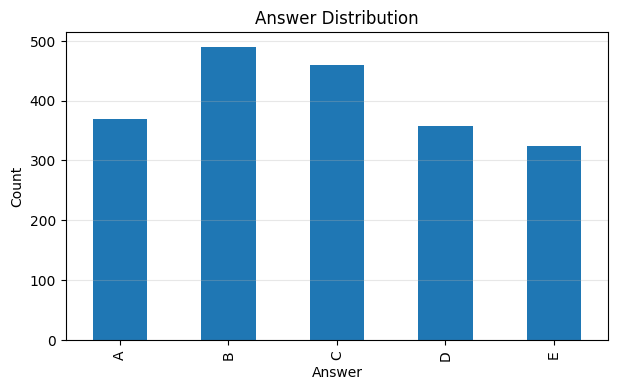

In [181]:
# ==========================================
# Target Distribution
# ==========================================

print(train["answer"].value_counts())

plt.figure(figsize=(7,4))

train["answer"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Answer Distribution")
plt.xlabel("Answer")
plt.ylabel("Count")
plt.grid(axis="y", alpha=0.3)

plt.show()

count    2000.000000
mean      117.669500
std        44.408674
min        19.000000
25%        87.750000
50%       111.000000
75%       141.000000
max       337.000000
Name: prompt_length, dtype: float64


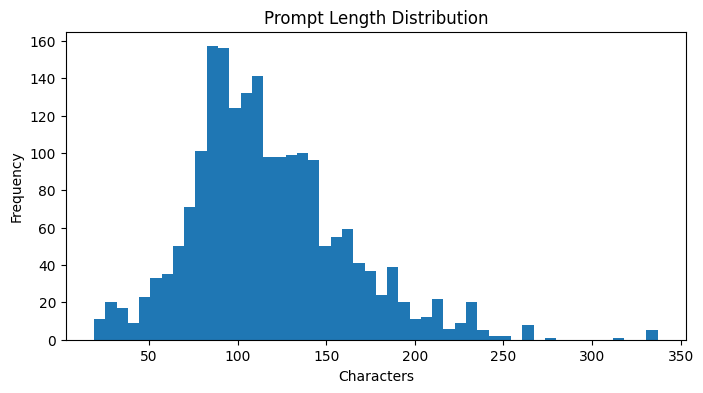

In [182]:
# ==========================================
# Prompt Length
# ==========================================

train["prompt_length"] = train["prompt"].astype(str).apply(len)

print(train["prompt_length"].describe())

plt.figure(figsize=(8,4))

plt.hist(train["prompt_length"], bins=50)

plt.title("Prompt Length Distribution")
plt.xlabel("Characters")
plt.ylabel("Frequency")

plt.show()

count    2000.000000
mean      942.398000
std       521.720751
min        84.000000
25%       566.000000
50%       870.500000
75%      1258.000000
max      2603.000000
Name: combined_length, dtype: float64


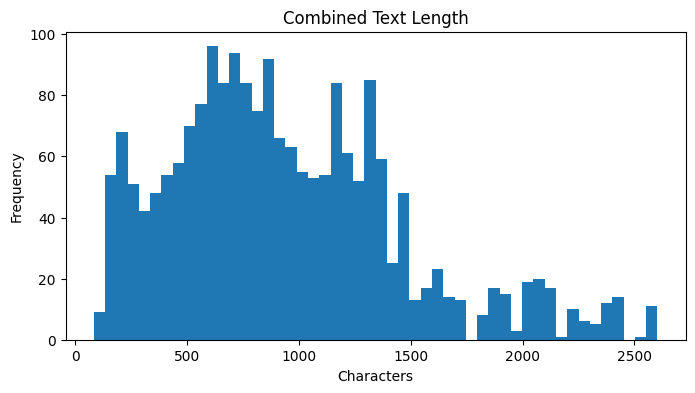

In [183]:
# ==========================================
# Combined Text Length
# ==========================================

train["combined_length"] = (
    train["prompt"].astype(str) +
    train["A"].astype(str) +
    train["B"].astype(str) +
    train["C"].astype(str) +
    train["D"].astype(str) +
    train["E"].astype(str)
).apply(len)

print(train["combined_length"].describe())

plt.figure(figsize=(8,4))

plt.hist(train["combined_length"], bins=50)

plt.title("Combined Text Length")
plt.xlabel("Characters")
plt.ylabel("Frequency")

plt.show()

In [184]:
# ==========================================
# Label Balance
# ==========================================

label_percent = (
    train["answer"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

display(label_percent)

answer
A    18.45
B    24.50
C    22.95
D    17.90
E    16.20
Name: proportion, dtype: float64

In [185]:
# ==========================================
# STEP 3 : Text Cleaning
# ==========================================

import re
import string

def clean_text(text):
    """
    Clean text while preserving sentence meaning.
    """

    if pd.isna(text):
        return ""

    text = str(text)

    # Lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Remove multiple spaces
    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [186]:
# ==========================================
# Clean All Text Columns
# ==========================================

text_columns = ["prompt", "A", "B", "C", "D", "E"]

for col in text_columns:
    train[col] = train[col].apply(clean_text)
    test[col] = test[col].apply(clean_text)

print("Text Cleaning Completed.")

Text Cleaning Completed.


In [187]:
# ==========================================
# Create Combined Text
# ==========================================

def combine_text(row):

    return (
        "Question: " + row["prompt"] +
        " [SEP] Option A: " + row["A"] +
        " [SEP] Option B: " + row["B"] +
        " [SEP] Option C: " + row["C"] +
        " [SEP] Option D: " + row["D"] +
        " [SEP] Option E: " + row["E"]
    )

train["combined_text"] = train.apply(combine_text, axis=1)
test["combined_text"] = test.apply(combine_text, axis=1)

print("Combined Text Created.")

Combined Text Created.


In [188]:
print(train["combined_text"].iloc[0])

Question: pick the best possible answer: what is martin heidegger's view on the relationship between time and human existence? among the listed options. [SEP] Option A: martin heidegger believes that humans exist within a time continuum that is infinite and does not have a defined beginning or end. the relationship to the past involves acknowledging it as a historical era, and the relationship to the future involves creating a world that will endure beyond one's own time. [SEP] Option B: martin heidegger believes that humans do not exist inside time, but that they are time. the relationship to the past is a present awareness of having been, and the relationship to the future involves anticipating a potential possibility, task, or engagement. [SEP] Option C: martin heidegger does not believe in the existence of time or that it has any effect on human consciousness. the relationship to the past and the future is insignificant, and human existence is solely based on the present. [SEP] Opt

In [189]:
train["num_words"] = train["combined_text"].apply(
    lambda x: len(x.split())
)

print(train["num_words"].describe())

count    2000.000000
mean      165.544500
std        85.412603
min        31.000000
25%       104.000000
50%       149.000000
75%       218.000000
max       473.000000
Name: num_words, dtype: float64


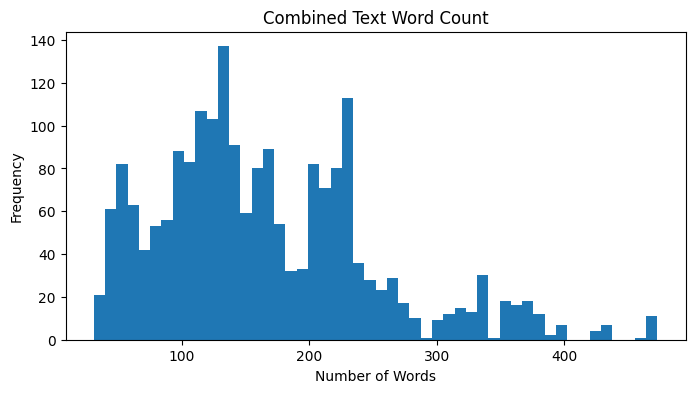

In [190]:
plt.figure(figsize=(8,4))

plt.hist(
    train["num_words"],
    bins=50
)

plt.title("Combined Text Word Count")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

In [191]:
print("95th Percentile Length")

print(np.percentile(train["num_words"],95))

95th Percentile Length
338.0


In [192]:
MAX_LEN = 384

In [193]:
# ==========================================
# STEP 4 : Label Encoding
# ==========================================

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

train["label"] = label_encoder.fit_transform(train["answer"])

print(label_encoder.classes_)
print(train[["answer", "label"]].head())

['A' 'B' 'C' 'D' 'E']
  answer  label
0      B      1
1      A      0
2      C      2
3      B      1
4      A      0


In [194]:
label2id = {label: idx for idx, label in enumerate(label_encoder.classes_)}
id2label = {idx: label for label, idx in label2id.items()}

print(label2id)
print(id2label)

{'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4}
{0: 'A', 1: 'B', 2: 'C', 3: 'D', 4: 'E'}


In [195]:
# ==========================================
# Tokenizer
# ==========================================

tokenizer = Tokenizer(
    num_words=MAX_VOCAB_SIZE,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(train["combined_text"])

print("Vocabulary Size :", len(tokenizer.word_index))

Vocabulary Size : 3037


In [196]:
train_sequences = tokenizer.texts_to_sequences(train["combined_text"])
test_sequences = tokenizer.texts_to_sequences(test["combined_text"])

In [197]:
print(train["combined_text"].iloc[0])

print("\nSequence:\n")

print(train_sequences[0][:50])

Question: pick the best possible answer: what is martin heidegger's view on the relationship between time and human existence? among the listed options. [SEP] Option A: martin heidegger believes that humans exist within a time continuum that is infinite and does not have a defined beginning or end. the relationship to the past involves acknowledging it as a historical era, and the relationship to the future involves creating a world that will endure beyond one's own time. [SEP] Option B: martin heidegger believes that humans do not exist inside time, but that they are time. the relationship to the past is a present awareness of having been, and the relationship to the future involves anticipating a potential possibility, task, or engagement. [SEP] Option C: martin heidegger does not believe in the existence of time or that it has any effect on human consciousness. the relationship to the past and the future is insignificant, and human existence is solely based on the present. [SEP] Opt

In [198]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

X = pad_sequences(
    train_sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test = pad_sequences(
    test_sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

y = train["label"].values

In [199]:
print("Training Shape :", X.shape)
print("Test Shape     :", X_test.shape)
print("Labels Shape   :", y.shape)

Training Shape : (2000, 384)
Test Shape     : (500, 384)
Labels Shape   : (2000,)


In [200]:
print(MAX_LEN)

384


In [201]:
sequence_lengths = [len(seq) for seq in train_sequences]

print("Maximum Sequence Length :", max(sequence_lengths))
print("Average Sequence Length :", np.mean(sequence_lengths))
print("95th Percentile         :", np.percentile(sequence_lengths, 95))

Maximum Sequence Length : 497
Average Sequence Length : 168.0585
95th Percentile         : 339.0


In [202]:
# ==========================================
# STEP 5 : Load GloVe Embeddings
# ==========================================

GLOVE_PATH = "/kaggle/input/datasets/danielwillgeorge/glove6b100dtxt/glove.6B.100d.txt"

print("Using GloVe File:")
print(GLOVE_PATH)

Using GloVe File:
/kaggle/input/datasets/danielwillgeorge/glove6b100dtxt/glove.6B.100d.txt


In [203]:
# ==========================================
# Load GloVe Embeddings
# ==========================================

embeddings_index = {}

with open(GLOVE_PATH, encoding="utf8") as f:

    for line in f:

        values = line.split()

        word = values[0]

        vector = np.asarray(values[1:], dtype="float32")

        embeddings_index[word] = vector

print("Total GloVe Words Loaded :", len(embeddings_index))

Total GloVe Words Loaded : 400000


In [204]:
# ==========================================
# Vocabulary Information
# ==========================================

word_index = tokenizer.word_index

print("Vocabulary Size :", len(word_index))

Vocabulary Size : 3037


In [205]:
# ==========================================
# Create Embedding Matrix
# ==========================================

vocab_size = min(MAX_VOCAB_SIZE, len(word_index) + 1)

embedding_matrix = np.zeros((vocab_size, EMBEDDING_DIM))

for word, idx in word_index.items():

    if idx >= vocab_size:
        continue

    vector = embeddings_index.get(word)

    if vector is not None:
        embedding_matrix[idx] = vector

In [206]:
# ==========================================
# Check Coverage
# ==========================================

found = 0

for word, idx in word_index.items():

    if idx >= vocab_size:
        continue

    if word in embeddings_index:
        found += 1

coverage = found / vocab_size

print(f"Vocabulary Covered : {found}")
print(f"Coverage           : {coverage:.2%}")

Vocabulary Covered : 2877
Coverage           : 94.70%


In [207]:
print("Embedding Matrix Shape")

print(embedding_matrix.shape)

Embedding Matrix Shape
(3038, 100)


In [208]:
word = "python"

if word in word_index:

    idx = word_index[word]

    print("Index :", idx)

    print("Embedding Vector:")

    print(embedding_matrix[idx][:15])

In [209]:
# ==========================================
# STEP 6 : Custom Attention Layer
# ==========================================

from tensorflow.keras.layers import Layer
import tensorflow.keras.backend as K

class AttentionLayer(Layer):

    def __init__(self, **kwargs):
        super(AttentionLayer, self).__init__(**kwargs)

    def build(self, input_shape):

        self.W = self.add_weight(
            name="attention_weight",
            shape=(input_shape[-1], 1),
            initializer="glorot_uniform",
            trainable=True,
        )

        self.b = self.add_weight(
            name="attention_bias",
            shape=(input_shape[1], 1),
            initializer="zeros",
            trainable=True,
        )

        super(AttentionLayer, self).build(input_shape)

    def call(self, inputs):

        # Alignment scores
        e = K.tanh(K.dot(inputs, self.W) + self.b)

        # Attention weights
        a = K.softmax(e, axis=1)

        # Weighted hidden states
        output = inputs * a

        # Context Vector
        context = K.sum(output, axis=1)

        return context

In [210]:
dummy = tf.random.normal((2, 256, 128))

attention = AttentionLayer()

output = attention(dummy)

print(output.shape)

(2, 128)


In [211]:
# ==========================================
# STEP 7 : Build BiLSTM + Attention Model
# ==========================================

from tensorflow.keras.layers import (
    Input,
    Embedding,
    Bidirectional,
    LSTM,
    Dense,
    Dropout,
    SpatialDropout1D
)
from tensorflow.keras.models import Model

def build_model():

    inputs = Input(shape=(MAX_LEN,), name="Input")

    # ---------------------------------------------------
    # Embedding Layer (Pretrained GloVe)
    # ---------------------------------------------------
    x = Embedding(
        input_dim=vocab_size,
        output_dim=EMBEDDING_DIM,
        weights=[embedding_matrix],
        input_length=MAX_LEN,
        trainable=False,          # Freeze GloVe initially
        name="Embedding"
    )(inputs)

    x = SpatialDropout1D(0.3)(x)

    # ---------------------------------------------------
    # First BiLSTM
    # ---------------------------------------------------
    x = Bidirectional(
        LSTM(
            128,
            return_sequences=True,
            dropout=0.3,
            recurrent_dropout=0.3
        )
    )(x)

    # ---------------------------------------------------
    # Second BiLSTM
    # ---------------------------------------------------
    x = Bidirectional(
        LSTM(
            64,
            return_sequences=True,
            dropout=0.3,
            recurrent_dropout=0.3
        )
    )(x)

    # ---------------------------------------------------
    # Attention Layer
    # ---------------------------------------------------
    x = AttentionLayer()(x)

    # ---------------------------------------------------
    # Dense Layers
    # ---------------------------------------------------
    x = Dense(256, activation="relu")(x)

    x = Dropout(0.4)(x)

    x = Dense(128, activation="relu")(x)

    x = Dropout(0.3)(x)

    outputs = Dense(
        5,
        activation="softmax",
        name="Output"
    )(x)

    model = Model(inputs, outputs)

    return model

In [212]:
model = build_model()

In [213]:
model.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input (InputLayer)              │ (None, 384)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Embedding (Embedding)           │ (None, 384, 100)       │       303,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_4             │ (None, 384, 100)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_8 (Bidirectional) │ (None, 384, 256)       │       234,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_9 (Bidirectional) │ (None, 384, 128)       │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention_layer_7               │ (None, 128)            │           512 │
│ (AttentionLayer)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 769,725 (2.94 MB)

 Trainable params: 465,925 (1.78 MB)

 Non-trainable params: 303,800 (1.16 MB)

In [214]:
# ==========================================
# STEP 8 : Compile Model
# ==========================================

from tensorflow.keras.optimizers import Adam

In [215]:
model.compile(
    optimizer=Adam(
        learning_rate=1e-3
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

In [216]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

In [217]:
early_stop = EarlyStopping(

    monitor="val_loss",

    patience=3,

    restore_best_weights=True,

    verbose=1
)

In [218]:
reduce_lr = ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=2,

    min_lr=1e-6,

    verbose=1
)

In [219]:
checkpoint = ModelCheckpoint(

    "best_model.keras",

    monitor="val_loss",

    save_best_only=True,

    verbose=1
)

In [220]:
callbacks = [

    early_stop,

    reduce_lr,

    checkpoint
]

In [221]:
model.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input (InputLayer)              │ (None, 384)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Embedding (Embedding)           │ (None, 384, 100)       │       303,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_4             │ (None, 384, 100)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_8 (Bidirectional) │ (None, 384, 256)       │       234,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_9 (Bidirectional) │ (None, 384, 128)       │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention_layer_7               │ (None, 128)            │           512 │
│ (AttentionLayer)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 769,725 (2.94 MB)

 Trainable params: 465,925 (1.78 MB)

 Non-trainable params: 303,800 (1.16 MB)

In [222]:
# ==========================================
# STEP 9 : 5 Fold Cross Validation
# ==========================================

from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

In [223]:
# Validation predictions
oof_pred = np.zeros((len(train), 5))

# Test predictions
test_pred = np.zeros((len(test), 5))

In [224]:
fold_accuracy = []
fold_losses = []

In [225]:
for fold, (train_idx, valid_idx) in enumerate(skf.split(X, y), 1):

    print("="*60)
    print(f"Fold {fold}")
    print("="*60)

    X_train = X[train_idx]
    X_valid = X[valid_idx]

    y_train = y[train_idx]
    y_valid = y[valid_idx]

Fold 1
Fold 2
Fold 3
Fold 4
Fold 5


In [226]:
    model = build_model()

    model.compile(
        optimizer=Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

In [227]:
    history = model.fit(

        X_train,
        y_train,

        validation_data=(X_valid, y_valid),

        epochs=20,

        batch_size=BATCH_SIZE,

        callbacks=callbacks,

        verbose=1
    )

Epoch 1/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.2404 - loss: 1.6062
Epoch 1: val_loss improved from None to 1.59882, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 119s 2s/step - accuracy: 0.2313 - loss: 1.6037 - val_accuracy: 0.2650 - val_loss: 1.5988 - learning_rate: 0.0010
Epoch 2/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.2440 - loss: 1.6042
Epoch 2: val_loss improved from 1.59882 to 1.58124, saving model to best_model.keras

Epoch 2: finished saving model to best_model.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 108s 2s/step - accuracy: 0.2519 - loss: 1.5963 - val_accuracy: 0.2575 - val_loss: 1.5812 - learning_rate: 0.0010
Epoch 3/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.2455 - loss: 1.5946
Epoch 3: val_loss improved from 1.58124 to 1.56164, saving model to best_model.keras

Epoch 3: finished saving model to best_model.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 110s 2s/step - accuracy: 0.2469 - lo

In [228]:
    valid_prob = model.predict(
        X_valid,
        verbose=0
    )

    oof_pred[valid_idx] = valid_prob

In [229]:
    fold_test = model.predict(
        X_test,
        verbose=0
    )

    test_pred += fold_test / skf.n_splits

In [230]:
    pred_label = np.argmax(valid_prob, axis=1)

    acc = accuracy_score(
        y_valid,
        pred_label
    )

    fold_accuracy.append(acc)

    print(f"Fold {fold} Accuracy : {acc:.4f}")

Fold 5 Accuracy : 0.9450


In [231]:
print("="*60)

print("Cross Validation Finished")

print("="*60)

Cross Validation Finished


In [232]:
overall_pred = np.argmax(oof_pred, axis=1)

overall_acc = accuracy_score(
    y,
    overall_pred
)

print(f"\nOverall Accuracy : {overall_acc:.4f}")


Overall Accuracy : 0.3370


In [233]:
# ==========================================
# STEP 10 : Top-3 Predictions
# ==========================================

top3_indices = np.argsort(test_pred, axis=1)[:, -3:]

In [234]:
top3_indices = top3_indices[:, ::-1]

In [235]:
predictions = []

for row in top3_indices:

    labels = [id2label[i] for i in row]

    predictions.append(" ".join(labels))

In [236]:
submission = pd.DataFrame({

    "id": test["id"],

    "Prediction": predictions

})

In [237]:
submission.head()

,id,Prediction
0,1,A C B
1,2,B A C
2,3,B A C
3,4,E A C
4,5,C A D


In [238]:
submission.to_csv(

    "submission.csv",

    index=False
)

print("Submission Saved Successfully!")

Submission Saved Successfully!


In [239]:
submission.sample(10)

,id,Prediction
361,362,B C A
73,74,D C A
374,375,E A C
155,156,D C A
104,105,E A C
394,395,A C D
377,378,A C E
124,125,D C B
68,69,E A C
450,451,D C A


In [240]:
def mapk(actual, predicted, k=3):

    score = 0.0

    for a, p in zip(actual, predicted):

        if a in p[:k]:

            score += 1.0 / (p.index(a) + 1)

    return score / len(actual)

In [241]:
oof_top3 = np.argsort(oof_pred, axis=1)[:, -3:][:, ::-1]

oof_labels = []

for row in oof_top3:
    oof_labels.append([id2label[i] for i in row])

actual = train["answer"].tolist()

score = mapk(actual, oof_labels, k=3)

print(f"Validation MAP@3 : {score:.5f}")

Validation MAP@3 : 0.45542
